**The program for simulation of two-photon Rydberg excitation of 36D_{3/2} state in the external DC electric field. Supplemental material for the paper S.A.Spirin et al. Three-dimensional three-photon Stark spectroscopy of single Rydberg Rb atoms in an ultrahigh-vacuum glass cell with eight electrodes**

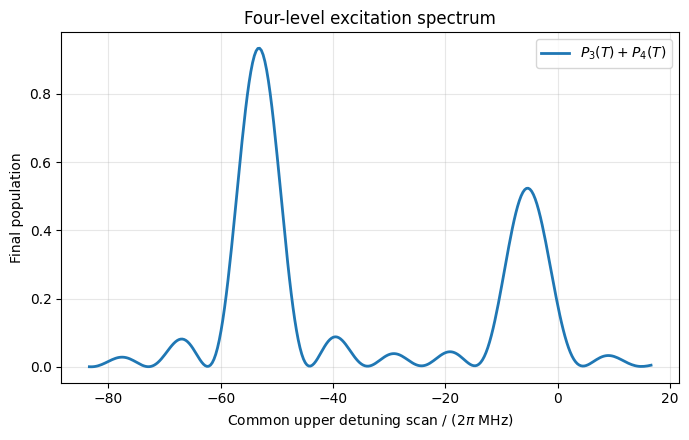

Final populations:
P1 = 0.817242
P2 = 0.003366
P3 = 0.006065
P4 = 0.173327
P3 + P4 = 0.179392


In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
import csv

# ============================================================
# Units
# ============================================================
MHz = 2 * np.pi * 1e6   # 1 MHz in angular-frequency units


# ============================================================
# Basis and operators for 4-level system
#
# Indices:
# |1> -> 0
# |2> -> 1
# |3> -> 2
# |4> -> 3
#
# Couplings:
# |1> <-> |2>
# |2> <-> |3>
# |2> <-> |4>
# ============================================================
def four_level_ops():
    N = 4
    kets = [qt.basis(N, i) for i in range(N)]
    P = [k * k.dag() for k in kets]

    # spontaneous decay lowering operators
    s21 = kets[0] * kets[1].dag()   # |1><2|
    s32 = kets[1] * kets[2].dag()   # |2><3|
    s42 = kets[1] * kets[3].dag()   # |2><4|

    # coherent coupling operators
    x12 = kets[0] * kets[1].dag() + kets[1] * kets[0].dag()
    x23 = kets[1] * kets[2].dag() + kets[2] * kets[1].dag()
    x24 = kets[1] * kets[3].dag() + kets[3] * kets[1].dag()

    return kets, P, s21, s32, s42, x12, x23, x24


# ============================================================
# Hamiltonian in the rotating-wave approximation
#
# Detunings:
# Delta12 : laser driving |1> <-> |2>
# Delta23 : laser driving |2> <-> |3>
# Delta24 : laser driving |2> <-> |4>
#
# In the rotating frame:
# E2 -> -Delta12
# E3 -> -(Delta12 + Delta23)
# E4 -> -(Delta12 + Delta24)
# ============================================================
def branching_hamiltonian(Omega12, Omega23, Omega24,
                          Delta12, Delta23, Delta24):
    _, P, _, _, _, x12, x23, x24 = four_level_ops()

    H_det = (
        -Delta12 * P[1]-Delta23 * P[2]-Delta24 * P[3]
    )

    H_drive = (
        0.5 * Omega12 * x12
        + 0.5 * Omega23 * x23
        + 0.5 * Omega24 * x24
    )

    return H_det + H_drive


# ============================================================
# Collapse operators
#
# Lifetimes:
# tau2 : |2> -> |1|
# tau3 : |3> -> |2|
# tau4 : |4> -> |2|
#
# Laser linewidth dephasing:
# gammaL12, gammaL23, gammaL24
# ============================================================
def collapse_operators(tau2=np.inf, tau3=np.inf, tau4=np.inf,
                       gammaL12=0.0, gammaL23=0.0, gammaL24=0.0):
    _, P, s21, s32, s42, _, _, _ = four_level_ops()
    c_ops = []

    # spontaneous decay
    if np.isfinite(tau2) and tau2 > 0:
        c_ops.append(np.sqrt(1.0 / tau2) * s21)

    if np.isfinite(tau3) and tau3 > 0:
        c_ops.append(np.sqrt(1.0 / tau3) * s32)

    if np.isfinite(tau4) and tau4 > 0:
        c_ops.append(np.sqrt(1.0 / tau4) * s42)

    # laser-linewidth dephasing
    if gammaL12 > 0:
        c_ops.append(np.sqrt(gammaL12 / 2.0) * (P[1] - P[0]))

    if gammaL23 > 0:
        c_ops.append(np.sqrt(gammaL23 / 2.0) * (P[2] - P[1]))

    if gammaL24 > 0:
        c_ops.append(np.sqrt(gammaL24 / 2.0) * (P[3] - P[1]))

    return c_ops


# ============================================================
# Solver options for stiff systems
# ============================================================
def make_solver_options(Omega12, Omega23, Omega24,
                        tau2=np.inf, tau3=np.inf, tau4=np.inf,
                        gammaL12=0.0, gammaL23=0.0, gammaL24=0.0):
    rates = [
        abs(Omega12), abs(Omega23), abs(Omega24),
        gammaL12, gammaL23, gammaL24
    ]

    if np.isfinite(tau2) and tau2 > 0:
        rates.append(1.0 / tau2)
    if np.isfinite(tau3) and tau3 > 0:
        rates.append(1.0 / tau3)
    if np.isfinite(tau4) and tau4 > 0:
        rates.append(1.0 / tau4)

    fastest_rate = max(rates) if max(rates) > 0 else 1.0
    max_step = 0.05 / fastest_rate

    return {
        "method": "bdf",
        "nsteps": 500000,
        "atol": 1e-8,
        "rtol": 1e-6,
        "max_step": max_step
    }


# ============================================================
# Final populations only
#
# Returns:
#   pops = [P1, P2, P3, P4]
#   P34  = P3 + P4
#   rhoT = final density matrix
# ============================================================
def final_populations(T,
                      Omega12, Omega23, Omega24,
                      Delta12, Delta23, Delta24,
                      tau2=np.inf, tau3=np.inf, tau4=np.inf,
                      gammaL12=0.0, gammaL23=0.0, gammaL24=0.0,
                      rho0=None):
    kets, P, *_ = four_level_ops()

    if rho0 is None:
        rho0 = qt.ket2dm(kets[0])

    H = branching_hamiltonian(
        Omega12, Omega23, Omega24,
        Delta12, Delta23, Delta24
    )

    c_ops = collapse_operators(
        tau2=tau2, tau3=tau3, tau4=tau4,
        gammaL12=gammaL12, gammaL23=gammaL23, gammaL24=gammaL24
    )

    opts = make_solver_options(
        Omega12, Omega23, Omega24,
        tau2=tau2, tau3=tau3, tau4=tau4,
        gammaL12=gammaL12, gammaL23=gammaL23, gammaL24=gammaL24
    )

    result = qt.mesolve(H, rho0, [0.0, T], c_ops, e_ops=[], options=opts)

    rhoT = result.states[-1]
    pops = np.array([qt.expect(Pi, rhoT) for Pi in P], dtype=float)
    P34 = pops[2] + pops[3]

    return pops, P34, rhoT


# ============================================================
# Simultaneous scan of detunings for states 3 and 4
#
# Common scan variable:
#   Delta_scan
#
# Actual detunings:
#   Delta23 = Delta_scan + delta3_offset
#   Delta24 = Delta_scan + delta4_offset
# ============================================================
def excitation_spectrum_upper_scan(scan_values,
                                   T,
                                   Omega12, Omega23, Omega24,
                                   Delta12,
                                   delta3_offset=0.0,
                                   delta4_offset=0.0,
                                   tau2=np.inf, tau3=np.inf, tau4=np.inf,
                                   gammaL12=0.0, gammaL23=0.0, gammaL24=0.0,
                                   rho0=None):
    all_pops = np.zeros((len(scan_values), 4), dtype=float)
    spectrum = np.zeros(len(scan_values), dtype=float)
    Delta23_values = np.zeros(len(scan_values), dtype=float)
    Delta24_values = np.zeros(len(scan_values), dtype=float)

    for i, Delta_scan in enumerate(scan_values):
        Delta23 = Delta_scan + delta3_offset
        Delta24 = Delta_scan + delta4_offset

        pops, P34, _ = final_populations(
            T=T,
            Omega12=Omega12, Omega23=Omega23, Omega24=Omega24,
            Delta12=Delta12, Delta23=Delta23, Delta24=Delta24,
            tau2=tau2, tau3=tau3, tau4=tau4,
            gammaL12=gammaL12, gammaL23=gammaL23, gammaL24=gammaL24,
            rho0=rho0
        )

        all_pops[i, :] = pops
        spectrum[i] = P34
        Delta23_values[i] = Delta23
        Delta24_values[i] = Delta24

    return spectrum, all_pops, Delta23_values, Delta24_values


def save_spectrum_csv(filename,
                      scan_values,
                      Delta23_values,
                      Delta24_values,
                      all_pops,
                      spectrum,
                      detuning_unit=MHz):
    """
    Save scan results to a CSV file.

    Columns:
      scan_value, Delta23, Delta24, P1, P2, P3, P4, P34

    Detunings are saved in units of detuning_unit.
    For example, if detuning_unit = MHz, values are saved in MHz/(2*pi).
    """
    with open(filename, mode="w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "scan_value",
            "Delta23",
            "Delta24",
            "P1",
            "P2",
            "P3",
            "P4",
            "P34"
        ])

        for i in range(len(scan_values)):
            P1, P2, P3, P4 = all_pops[i]
            P34 = spectrum[i]
            writer.writerow([
                scan_values[i] / detuning_unit,
                Delta23_values[i] / detuning_unit,
                Delta24_values[i] / detuning_unit,
                P1,
                P2,
                P3,
                P4,
                P34
            ])

# ============================================================
# Example
# ============================================================
if __name__ == "__main__":
    # Fixed interaction time
    T = 1.0e-7

    # Rabi frequencies
    Omega12 =100.0 * MHz
    Omega23 =86.0 * MHz
    Omega24 =50.0 * MHz

    # Lower transition detuning
    Delta12 = 1000.0 * MHz
      
    Ex=0.0
    Ey=2.5
    Ez=0.0
    alpha12=0.545
    alpha32=8.416
    # Offsets of upper transitions relative to common scan
    delta3_offset = alpha32*(Ey**2+Ex**2+Ez**2)* MHz
    delta4_offset = alpha12*(Ey**2+Ex**2+Ez**2)* MHz

    # Lifetimes
    tau2 = 26e-9
    tau3 = 29e-6
    tau4 = 29e-6

    # Laser linewidth dephasing
    gammaL12 = 0.0 * MHz
    gammaL23 = 0.0 * MHz
    gammaL24 = 0.0 * MHz

    # Common scan of upper detunings
    detuning_scan = np.linspace(-80* MHz-delta4_offset,20*MHz- delta4_offset, 321)

    P34_spectrum, all_pops, Delta23_vals, Delta24_vals = excitation_spectrum_upper_scan(
        scan_values=detuning_scan,
        T=T,
        Omega12=Omega12,
        Omega23=Omega23,
        Omega24=Omega24,
        Delta12=Delta12,
        delta3_offset=delta3_offset,
        delta4_offset=delta4_offset,
        tau2=tau2, tau3=tau3, tau4=tau4,
        gammaL12=gammaL12, gammaL23=gammaL23, gammaL24=gammaL24
    )

    plt.figure(figsize=(7, 4.5))
    plt.plot(detuning_scan / MHz, P34_spectrum, lw=2, label=r"$P_3(T)+P_4(T)$")
    plt.xlabel(r'Common upper detuning scan / $(2\pi\ \mathrm{MHz})$')
    plt.ylabel(r'Final population')
    plt.title('Four-level excitation spectrum')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Example endpoint at one scan value
    Delta_scan0 = 0.0 * MHz
    Delta23_0 = Delta_scan0 + delta3_offset
    Delta24_0 = Delta_scan0 + delta4_offset

    pops_res, P34_res, rhoT_res = final_populations(
        T=T,
        Omega12=Omega12, Omega23=Omega23, Omega24=Omega24,
        Delta12=Delta12, Delta23=Delta23_0, Delta24=Delta24_0,
        tau2=tau2, tau3=tau3, tau4=tau4,
        gammaL12=gammaL12, gammaL23=gammaL23, gammaL24=gammaL24
    )

    print("Final populations:")
    print(f"P1 = {pops_res[0]:.6f}")
    print(f"P2 = {pops_res[1]:.6f}")
    print(f"P3 = {pops_res[2]:.6f}")
    print(f"P4 = {pops_res[3]:.6f}")
    print(f"P3 + P4 = {P34_res:.6f}")

In [30]:
save_spectrum_csv(
        filename="spectrum_scan.csv",
        scan_values=detuning_scan,
        Delta23_values=Delta23_vals,
        Delta24_values=Delta24_vals,
        all_pops=all_pops,
        spectrum=P34_spectrum,
        detuning_unit=MHz
    )